# TráficoIA · Control del semáforo con Q-learning
Un paso permite atender como máximo un auto por la vía verde. Simulamos llegadas independientes con probabilidades de 0.45 al norte-sur y 0.30 al este-oeste. Estos valores son supuestos del experimento. El agente observa ambas colas agrupadas de 0 a 4 (4 incluye cuatro o más autos) y la fase actual. Mantener o cambiar son sus dos acciones. El cambio cuesta un punto adicional a la penalización por cada auto que sigue esperando.

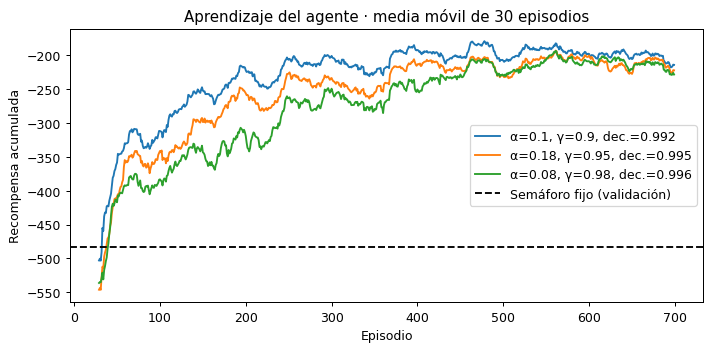

,alfa,gamma,decaimiento,retorno,espera
0,0.10,0.90,0.992,-199.62,1.179832
1,0.18,0.95,0.995,-378.40,2.673782
2,0.08,0.98,0.996,-560.94,4.186723


In [1]:
from pathlib import Path
import sys
if not (Path.cwd() / "src").is_dir():
    sys.path.insert(0, str(Path.cwd().parent))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src import config
from src.refuerzo import entrenar, evaluar

config.FIGURAS.mkdir(parents=True, exist_ok=True)
config.MODELOS.mkdir(parents=True, exist_ok=True)
ajustes = [(0.10, 0.90, 0.992), (0.18, 0.95, 0.995), (0.08, 0.98, 0.996)]
resultados = []
tablas = []
fig, ax = plt.subplots(figsize=(8, 4))
for alfa, gamma, decaimiento in ajustes:
    q, curva = entrenar(alfa, gamma, decaimiento)
    tablas.append(q)
    retorno, espera = evaluar(q, range(2000, 2050))
    resultados.append((alfa, gamma, decaimiento, retorno, espera))
    ax.plot(pd.Series(curva).rolling(30).mean(), label=f"α={alfa}, γ={gamma}, dec.={decaimiento}")
base, _ = evaluar(None, range(2000, 2050))
ax.axhline(base, linestyle="--", color="black", label="Semáforo fijo (validación)")
ax.set(xlabel="Episodio", ylabel="Recompensa acumulada", title="Aprendizaje del agente · media móvil de 30 episodios")
ax.legend()
fig.tight_layout()
fig.savefig(config.FIGURAS / "rl_aprendizaje.png", dpi=140)
plt.show()
validacion = pd.DataFrame(resultados, columns=["alfa", "gamma", "decaimiento", "retorno", "espera"])
display(validacion)
mejor = tablas[validacion.retorno.idxmax()]
np.save(config.MODELOS / "q_semaforo.npy", mejor)

## Comparación en 100 episodios nuevos
Elegimos la configuración por recompensa media en validación. Para la prueba, las dos políticas reciben las mismas llegadas y la misma fase inicial en cada episodio de 160 pasos. La espera se calcula como auto-pasos acumulados divididos entre todos los autos que llegaron. Cuenta la espera observada hasta el fin del episodio, incluso para autos que siguen en cola.

In [2]:
q_guardada = np.load(config.MODELOS / "q_semaforo.npy")
filas = []
for nombre, politica in [("Fijo (5 pasos por fase)", None), ("Q-learning", q_guardada)]:
    retorno, espera = evaluar(politica, range(5000, 5100))
    filas.append([nombre, retorno, espera])
prueba = pd.DataFrame(filas, columns=["Política", "Recompensa media", "Espera media (pasos/auto)"])
display(prueba)
prueba.to_csv(config.RAIZ / "reports" / "rl_comparacion.csv", index=False)
cambio = 100 * (1 - filas[1][2] / filas[0][2])
print(f"Reducción de la espera frente al ciclo fijo: {cambio:.1f} %. Resultado para las llegadas simuladas y el ciclo fijo de cinco pasos.")

Reducción de la espera frente al ciclo fijo: 69.7 %. Resultado para las llegadas simuladas y el ciclo fijo de cinco pasos.


,Política,Recompensa media,Espera media (pasos/auto)
0,Fijo (5 pasos por fase),-467.39,3.604146
1,Q-learning,-193.08,1.093244
